# Dataset Description

This directory contains the TSV and related files of the moreno\_crime network: This bipartite network contains persons who appeared in at least one crime case as either a suspect, a victim, a witness or both a suspect and victim at the same time\. A left node represents a person and a right node represents a crime\. An edge between two nodes shows that the left node was involved in the crime represented by the right node\.

Files: 
    meta\.moreno\_crime \-\- Metadata about the network 
    out\.moreno\_crime \-\- The adjacency matrix of the network in whitespace\-separated values format, with one edge per line
      The meaning of the columns in out\.moreno\_crime are: 
        First column: ID of from node 
        Second column: ID of to node
        Third column \(if present\): weight or multiplicity of edge
        Fourth column \(if present\):  timestamp of edges Unix time
    ent\.moreno\_crime\.person\.sex \-\- Contains the attribute \`sex\` of entity \`person\` of the network
    ent\.moreno\_crime\.person\.name \-\- Contains the attribute \`name\` of entity \`person\` of the network

# What is our research question?

From people side, centrality putting a threshold \(maybe look gender\)

From crime side, community detection, number in communities

How is the crime context shaped?

In [2]:
import networkx as nx
import matplotlib.pyplot as plt
import pickle
from networkx.algorithms import bipartite
from statsmodels.distributions.empirical_distribution import ECDF
import scipy.stats
import numpy as np
import seaborn as sns
import pandas as pd
#import community.community_louvain as community_louvain
import networkx.algorithms.community as nx_comm
#from infomap import Infomap
from collections import defaultdict
import csv
from typing import List

In [3]:
def combine_space_csv(file1, file2, output_file):
    # Read first file (space-separated)
    rows1 = []
    with open(file1) as f1:
        for line in f1:
            parts = line.strip().split()
            if parts:
                rows1.append(parts)

    # Read second file and skip its first row (header)
    rows2 = []
    with open(file2) as f2:
        reader = csv.reader(f2)
        for i, row in enumerate(reader):
            if any(cell.strip() for cell in row):
                rows2.append([cell.strip() for cell in row])

    # Pair line-by-line (shortest)
    out_len = min(len(rows1), len(rows2))

    with open(output_file, "w", newline="") as out:
        writer = csv.writer(out)
        for i in range(out_len):
            writer.writerow(rows1[i] + rows2[i])


In [4]:
combine_space_csv("out.moreno_crime_crime", "rel.moreno_crime_crime.person.role", "roles.txt")

In [5]:
def rename_columns(input_file, output_file):
    """
    Reads a txt file line-by-line and renames columns:
      - First column becomes:  p<value>
      - Other columns become: c<value>
    Writes the modified lines to a new txt file.
    """

    with open(input_file, "r") as infile, open(output_file, "w") as outfile:
        for line in infile:
            # Split line into columns (ignores extra whitespace)
            cols = line.strip().split()

            if not cols:
                outfile.write("\n")
                continue

            # Rename first column
            new_cols = [f"p{cols[0]}"]

            # Rename the remaining columns
            for col in cols[1:]:
                new_cols.append(f"c{col}")

            # Write the transformed line
            outfile.write(" ".join(new_cols) + "\n")


In [6]:
B = nx.Graph()

df = pd.read_csv("roles.txt", sep=",", header=None, names=["person_id","crime_id","role"])

# Add edges with attributes
for _, row in df.iterrows():

    person = row["person_id"]
    crime  = row["crime_id"]
    role   = row["role"]

    # Add nodes to the two partitions
    B.add_node(person, bipartite=0)
    B.add_node(crime, bipartite=1)

    # Add the edge with the role attribute
    B.add_edge(person, crime, role=role)

# Print edges with attributes
i=0
for u, v, data in B.edges(data=True):
    print(u, v, data)
    i+=1
    if i==9:
        break

1 1 {'role': 'Suspect'}
1 2 {'role': 'Victim'}
1 3 {'role': 'Victim'}
1 4 {'role': 'Suspect'}
1 756 {'role': 'Suspect'}
2 5 {'role': 'Victim'}
2 6 {'role': 'Suspect'}
2 7 {'role': 'Victim'}
2 8 {'role': 'Suspect'}


In [7]:
roles = set(d['role'] for _, _, d in B.edges(data=True))
print("Roles present:", roles)


Roles present: {'Witness', 'Victim', 'Suspect', 'Victim Suspect'}


In [8]:
# Filter edges with role == 'Suspect'
role_edges = [(u, v) for u, v, d in B.edges(data=True) if d['role'] == 'Suspect' or d['role'] == 'Victim Suspect']

# Create subgraph
B_suspects = B.edge_subgraph(role_edges).copy()  # always copy to avoid view issues

#for u, v, data in B_suspects.edges(data=True):
#    print(u, v, data['role'])

# Get people nodes in this subgraph
people_nodes_sub = [n for n, d in B_suspects.nodes(data=True) if d['bipartite'] == 0]

G_people_suspects = bipartite.weighted_projected_graph(B_suspects, people_nodes_sub)

print(G_people_suspects)


Graph with 490 nodes and 945 edges


## Projection people: Centrality

In [9]:
def draw_network_colored(g, p, centrality, threshold=None):
    """
    g: graph
    p: layout dict
    centrality: dict node -> centrality value
    threshold: float or None. If set, only nodes with centrality >= threshold are shown.
    """

    # --- filter nodes if threshold is used ---
    if threshold is not None:
        selected_nodes = [n for n, c in centrality.items() if c >= threshold]
        if not selected_nodes:
            print("No nodes above threshold")
            return

        g = g.subgraph(selected_nodes)
        p = {n: p[n] for n in selected_nodes}
        centrality = {n: centrality[n] for n in selected_nodes}

    # --- compute node sizes based on centrality ---
    node_sizes = [300 + 2000 * c for c in centrality.values()]

    plt.figure(figsize=(13, 7))

    nx.draw_networkx_edges(
        g, p,
        alpha=0.3,
        width=0.7,
        edge_color='lightgrey'
    )

    nodes = nx.draw_networkx_nodes(
        g, p,
        node_color=list(centrality.values()),
        node_size=node_sizes,
        cmap=plt.cm.Blues
    )
    nodes.set_edgecolor('white')

    nx.draw_networkx_labels(
        g, p,
        font_size=10,
        font_weight='bold'
    )

    plt.axis("off")
    plt.show()


In [10]:
print(G_people_suspects.edges())


[(7, 648), (7, 467), (7, 60), (7, 486), (9, 6), (9, 8), (9, 10), (9, 11), (9, 12), (9, 13), (9, 15), (9, 16), (9, 17), (9, 18), (9, 20), (9, 21), (9, 22), (9, 24), (9, 25), (9, 26), (18, 6), (18, 8), (18, 10), (18, 11), (18, 12), (18, 13), (18, 15), (18, 16), (18, 17), (18, 20), (18, 21), (18, 22), (18, 86), (18, 24), (18, 25), (18, 26), (64, 584), (64, 10), (64, 56), (64, 185), (64, 184), (66, 544), (66, 65), (66, 130), (66, 289), (66, 545), (66, 520), (66, 10), (66, 366), (66, 285), (74, 636), (74, 609), (74, 515), (74, 72), (74, 169), (74, 51), (74, 533), (74, 188), (74, 190), (76, 449), (76, 637), (76, 425), (76, 695), (76, 497), (76, 114), (76, 278), (76, 54), (76, 409), (76, 346), (76, 413), (76, 95), (89, 19), (89, 20), (89, 90), (89, 91), (89, 92), (103, 152), (103, 106), (103, 786), (113, 356), (113, 45), (113, 78), (113, 433), (113, 114), (113, 116), (113, 117), (113, 145), (113, 146), (113, 539), (123, 122), (123, 91), (123, 396), (123, 397), (123, 110), (123, 244), (123, 90

### Degree centrality

In [26]:
degree_centrality = nx.degree_centrality(G_people_suspects)
#degree_centrality

In [50]:
degree=dict(nx.degree(G_people_suspects))
degree_centrality = {n: round(c/(G_people_suspects.order()-1),4) for n,c in degree.items()}
node_d_centr = list(degree_centrality.items())
node_d_centr.sort(key = lambda x: x[1], reverse = True)
#print(node_d_centr[:10])
vals = list(degree_centrality.values())
deg_threshold = np.percentile(vals, 95)
#print(threshold)

In [32]:
## Observations

crime_count = {p: B.degree(p) for p in G_people_suspects.nodes()}
for p, dc in node_d_centr[:10]:
    print(p, "degree_centrality:", dc, "num_crimes:", crime_count[p])


815 degree_centrality: 0.0552 num_crimes: 25
285 degree_centrality: 0.047 num_crimes: 2
178 degree_centrality: 0.0429 num_crimes: 2
695 degree_centrality: 0.0389 num_crimes: 11
715 degree_centrality: 0.0389 num_crimes: 12
430 degree_centrality: 0.0368 num_crimes: 2
18 degree_centrality: 0.0348 num_crimes: 2
281 degree_centrality: 0.0348 num_crimes: 2
286 degree_centrality: 0.0348 num_crimes: 2
95 degree_centrality: 0.0348 num_crimes: 14


In [35]:
# Build crime_sizes ONLY from the crimes the top people connect to
crime_sizes = {}

for p, dc in node_d_centr[:10]:
    for c in G_people_suspects.neighbors(p):
        # This collects any node that appears as a neighbor of a person
        crime_sizes[c] = G_people_suspects.degree(c)

results = []
for p, dc in node_d_centr[:10]:
    num_crimes = G_people_suspects.degree(p)
    cooffenders = sum((crime_sizes[c] - 1) for c in G_people_suspects.neighbors(p))
    avg_crime_size = cooffenders / num_crimes if num_crimes else 0
    results.append((p, dc, num_crimes, avg_crime_size))

results


[(815, 0.0552, 27, 1.8888888888888888),
 (285, 0.047, 23, 7.0),
 (178, 0.0429, 21, 7.761904761904762),
 (695, 0.0389, 19, 7.2631578947368425),
 (715, 0.0389, 19, 3.263157894736842),
 (430, 0.0368, 18, 7.0),
 (18, 0.0348, 17, 3.1176470588235294),
 (281, 0.0348, 17, 8.176470588235293),
 (286, 0.0348, 17, 8.529411764705882),
 (95, 0.0348, 17, 10.529411764705882)]

In [38]:
def centrality_explanation_table(B, centrality_dict, top_n=10, centrality_type="Degree"):
    """
    B: bipartite graph 
    centrality_dict: dict of {node: centrality_value} for the people nodes
    top_n: number of top people to display
    centrality_type: str, one of ["Degree", "Betweenness", "Closeness", "Eigenvector"]
    """
    
    # Sort people by the selected centrality
    sorted_people = sorted(centrality_dict.items(), key=lambda x: x[1], reverse=True)[:top_n]
    
    rows = []
    
    for p, cent_value in sorted_people:
        crimes = list(B.neighbors(p))                 # crimes connected to p
        num_crimes = len(crimes)                      # how many crimes
        
        # size of each crime (number of people involved)
        cooffenders_counts = [(B.degree(c) - 1) for c in crimes]
        
        total_cooffenders = sum(cooffenders_counts)
        avg_cooff = total_cooffenders / num_crimes if num_crimes else 0
        
        rows.append({
            "Person": p,
            f"{centrality_type} Centrality": cent_value,
            "Num Crimes": num_crimes,
            "Total Co-offenders": total_cooffenders,
            "Avg Co-offenders per Crime": round(avg_cooff, 3)
        })
    
    return pd.DataFrame(rows)



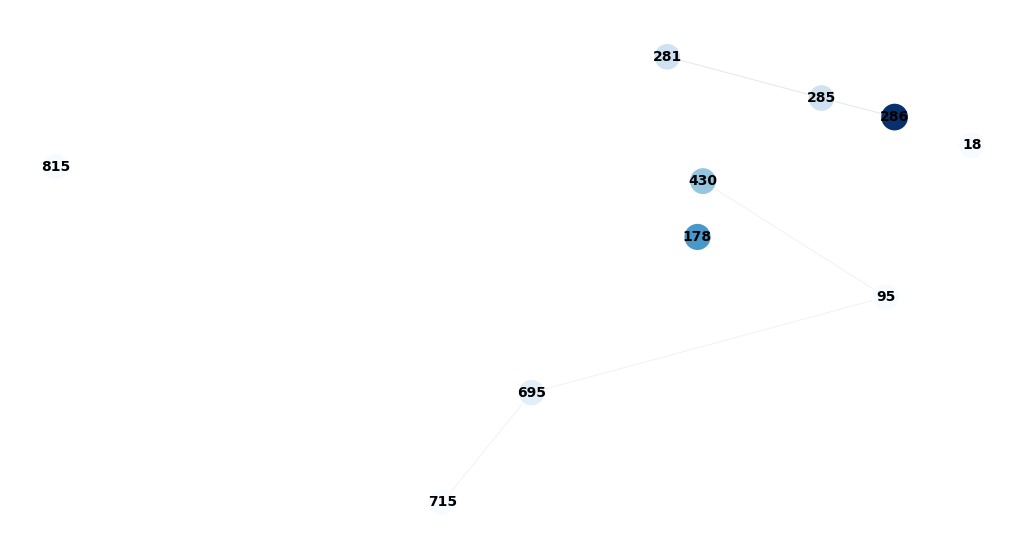

In [62]:
deg_threshold = np.percentile(vals, 98)
draw_network_colored(G_people_suspects, pos, degree_centrality, threshold=deg_threshold)

### Degree centrality interpretation

To investigate patterns of co\-offending in the crime dataset, a bipartite network was constructed with:People \(offenders\) as one node setCrimes \(criminal events\) as the other node setA one\-mode projection onto the people layer was then created, where two individuals are connected if they co\-participated in at least one crime\. Degree centrality was calculated to identify the individuals who are connected to the largest number of others in the projected network\.

In the projected people\-to\-people network:Degree = number of distinct co\-offenders an individual has collaborated with\.Degree centrality = degree normalized by the maximum possible degree \(N−1\)\.A high degree centrality can reflect:Multiple repeated offending across different crimesParticipation in crimes with large groupsA mix of bothHowever, bipartite projections create a known artifact:➤ Individuals involved in a single crime with many co\-offenders can appear artificially central\.Thus, interpreting degree centrality requires examining:Number of crimes per personSize of the co\-offender groups they participated inWe computed these two metrics to distinguish genuine repeat offenders from projection artifacts\.

In [65]:
df_degree_expl = centrality_explanation_table(G_people_suspects, nx.degree_centrality(G_people_suspects), top_n=10, centrality_type="Degree")
df_degree_expl


,Person,Degree Centrality,Num Crimes,Total Co-offenders,Avg Co-offenders per Crime
0,815,0.055215,27,51,1.889
1,285,0.047035,23,161,7.000
2,178,0.042945,21,163,7.762
3,695,0.038855,19,138,7.263
4,715,0.038855,19,62,3.263
5,430,0.036810,18,126,7.000
6,18,0.034765,17,53,3.118
7,281,0.034765,17,139,8.176
8,286,0.034765,17,145,8.529
9,95,0.034765,17,179,10.529


In [20]:
_dntk.DeepnoteChart(df_degree_expl, '{"mark":{"type":"bar","tooltip":true},"width":"container","config":{"customFormatTypes":true},"height":"container","$schema":"https://vega.github.io/schema/vega-lite/v5.json","encoding":{"x":{"sort":null,"type":"nominal","scale":{"type":"linear"},"format":{"type":"default","decimals":null}},"y":{"sort":null,"type":"nominal","scale":{"type":"linear"},"format":{"type":"default","decimals":null}}},"usermeta":{"tooltipDefaultMode":true}}', filters='[]')

### Closeness Centrality

In [68]:
closeness_centrality = nx.closeness_centrality(G_people_suspects)
node_c_centr = list(closeness_centrality.items())
node_c_centr.sort(key = lambda x: x[1], reverse = True)
print(node_c_centr[:10])

[(815, 0.23357057293493708), (695, 0.2323894322374153), (43, 0.22863189166641232), (76, 0.22389773556613335), (409, 0.22389773556613335), (637, 0.22389773556613335), (95, 0.21935565739832397), (592, 0.2168968034215876), (425, 0.21362003590911735), (715, 0.21250871780323177)]


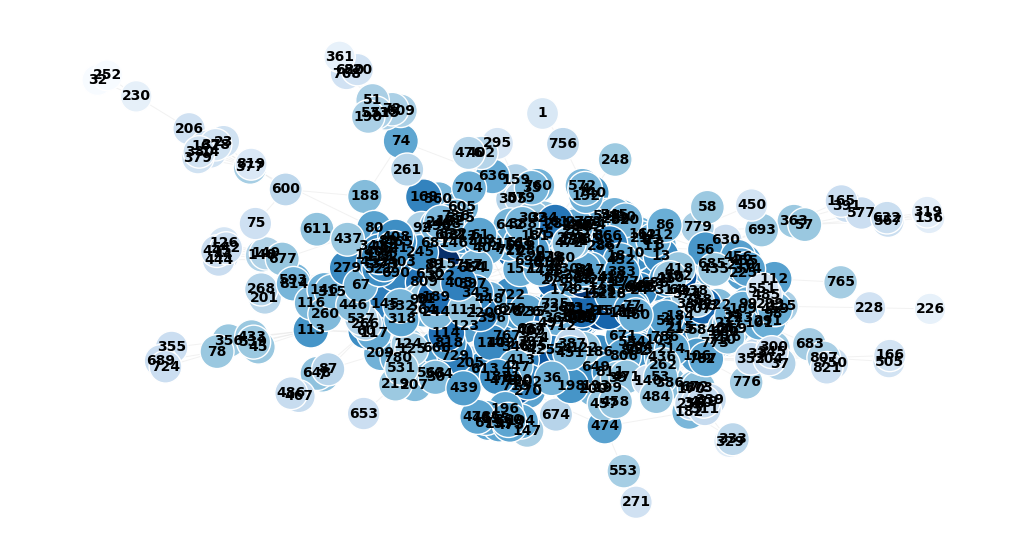

In [101]:
clos_threshold = np.percentile(vals, 95)
draw_network_colored(G_people_suspects, pos, closeness_centrality, threshold=clos_threshold)

In [107]:
df_closeness_expl = centrality_explanation_table(G_people_suspects, closeness_centrality, top_n=100, centrality_type="Closeness")
df_closeness_expl


,Person,Closeness Centrality,Num Crimes,Total Co-offenders,Avg Co-offenders per Crime
0,815,0.233571,27,51,1.889
1,695,0.232389,19,138,7.263
2,43,0.228632,8,115,14.375
3,76,0.223898,12,117,9.750
4,409,0.223898,12,117,9.750
...,...,...,...,...,...
95,397,0.181551,8,32,4.000
96,686,0.181282,13,86,6.615
97,643,0.181103,11,86,7.818
98,646,0.181103,11,86,7.818


### Betweenness Centrality

In [110]:
betweenness_centrality=nx.betweenness_centrality(G_people_suspects)
node_b_centr = list(betweenness_centrality.items())
node_b_centr.sort(key = lambda x: x[1], reverse = True)
node_b_centr[:10]

[(815, 0.19367521544611918),
 (95, 0.11713072284869715),
 (43, 0.10749568319533578),
 (695, 0.09801312291778651),
 (425, 0.07664479770393046),
 (715, 0.06930401614447143),
 (428, 0.06232161311853105),
 (592, 0.05951977657573042),
 (178, 0.05889090602648884),
 (278, 0.053962400288437073)]

In [113]:
df_betweenness_expl = centrality_explanation_table(G_people_suspects, betweenness_centrality, top_n=10, centrality_type="Betweenness")
df_betweenness_expl

,Person,Betweenness Centrality,Num Crimes,Total Co-offenders,Avg Co-offenders per Crime
0,815,0.193675,27,51,1.889
1,95,0.117131,17,179,10.529
2,43,0.107496,8,115,14.375
3,695,0.098013,19,138,7.263
4,425,0.076645,16,173,10.812
5,715,0.069304,19,62,3.263
6,428,0.062322,15,110,7.333
7,592,0.059520,14,41,2.929
8,178,0.058891,21,163,7.762
9,278,0.053962,10,146,14.600


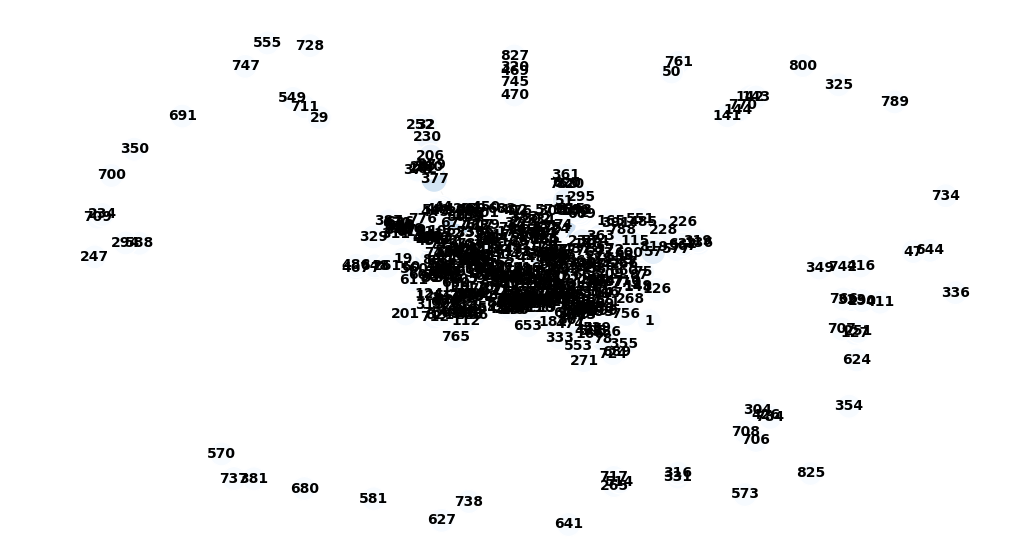

In [26]:
draw_network_colored(G_people_suspects, pos, betweenness_centrality)

### Eigenvector Centrality

In [116]:
eigenvector_centrality = nx.eigenvector_centrality(G_people_suspects, 300)
node_e_centr = list(eigenvector_centrality.items())
node_e_centr.sort(key = lambda x: x[1], reverse = True)
node_e_centr[:10]

[(285, 0.332099375888018),
 (281, 0.3026133913915162),
 (286, 0.30154730256994616),
 (283, 0.298911416128916),
 (273, 0.29349199784434993),
 (276, 0.29349199784434993),
 (278, 0.20212182770551046),
 (280, 0.17792937568452719),
 (287, 0.1741414235248158),
 (362, 0.17176658338767553)]

In [119]:
df_eigenvector_expl = centrality_explanation_table(G_people_suspects, eigenvector_centrality, top_n=10, centrality_type="Eigenvector")
df_eigenvector_expl

,Person,Eigenvector Centrality,Num Crimes,Total Co-offenders,Avg Co-offenders per Crime
0,285,0.332099,23,161,7.000
1,281,0.302613,17,139,8.176
2,286,0.301547,17,145,8.529
3,283,0.298911,16,137,8.562
4,273,0.293492,14,135,9.643
5,276,0.293492,14,135,9.643
6,278,0.202122,10,146,14.600
7,280,0.177929,9,108,12.000
8,287,0.174141,7,108,15.429
9,362,0.171767,6,95,15.833


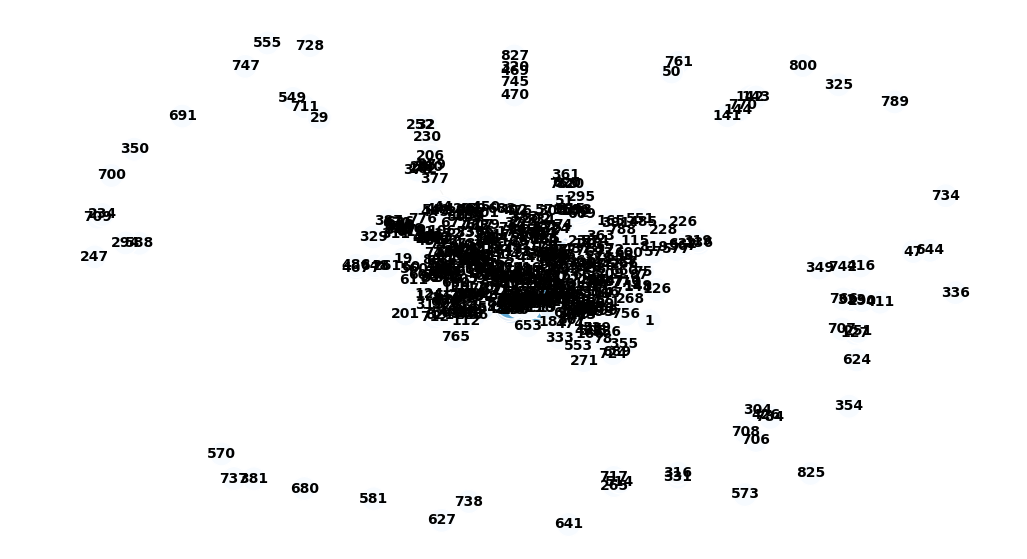

In [29]:
draw_network_colored(G_people_suspects, pos, eigenvector_centrality)

# Community Detection

In [30]:
def draw_community_graph(g, p, color_for_nodes, nodesize = 600):
    plt.figure(figsize = (15,7))

    nx.draw_networkx(
        g, pos=p,
        font_size = 12, 
        font_weight = 'bold',
        font_color = 'navy',
        edge_color = 'grey'
    )
    
    nodes = nx.draw_networkx_nodes(
        g, p,
        node_color=[color_for_nodes[n] for n in g.nodes()],
        node_size = nodesize
    )
                     
    nodes.set_edgecolor('lightgrey')
    plt.axis('off')
    plt.show()


# Louvain

In [31]:
# 1️⃣ Louvain partition
partition = community_louvain.best_partition(B_crimes)
num_communities = len(set(partition.values()))
print(f"Number of communities detected: {num_communities}")

NameError: name 'community_louvain' is not defined

In [31]:
def get_color_list(ncolors, cmap='Pastel1_r'):
    return mcp.gen_color(cmap=cmap, n=ncolors)

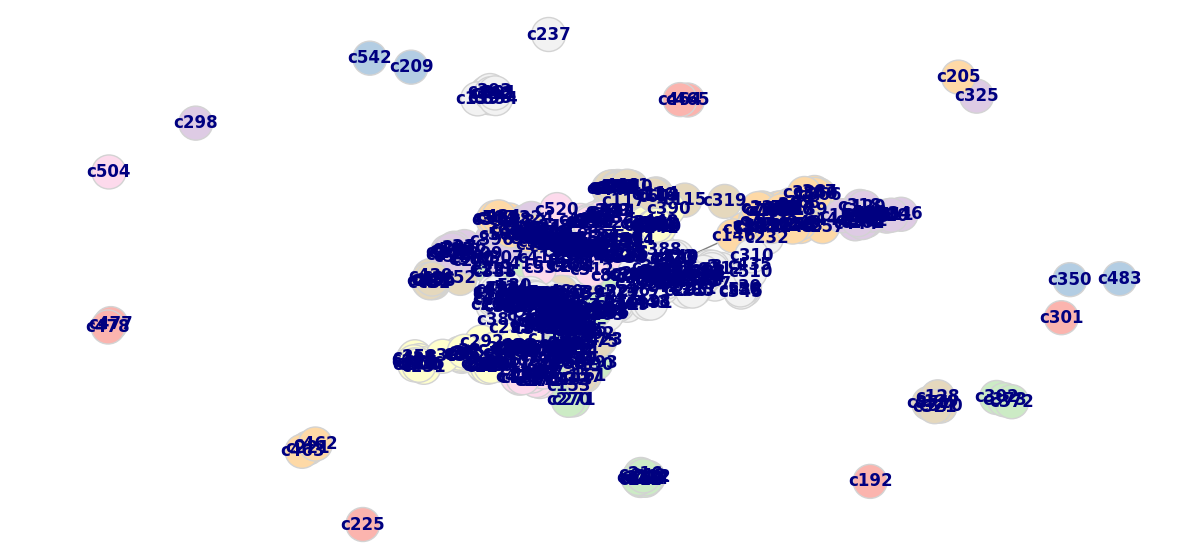

In [32]:
from community import community_louvain
from mycolorpy import colorlist as mcp
# --- Layout for crime projection ---
p_cr = nx.spring_layout(B_crimes)

# --- Louvain ---
partition_louvain_cr = community_louvain.best_partition(B_crimes)

# Assign a unique color to each community
comm_index = set(partition_louvain_cr.values())
colors_louvain = {
    comm: c for comm, c in zip(comm_index, get_color_list(len(comm_index), 'Pastel1_r'))
}

# Color for each node
colors_for_node_louvain_cr = {
    node: colors_louvain[c] for node, c in partition_louvain_cr.items()
}

# Draw
draw_community_graph(B_crimes, p_cr, colors_for_node_louvain_cr)


Number of communities detected: 39
Minimum community size: 1
Maximum community size: 62
Mean community size: 14.13
Median community size: 6.0


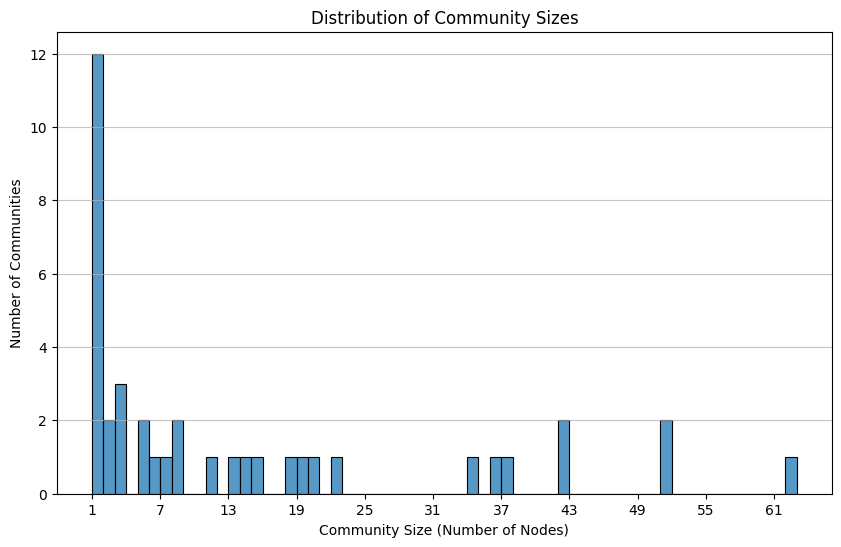

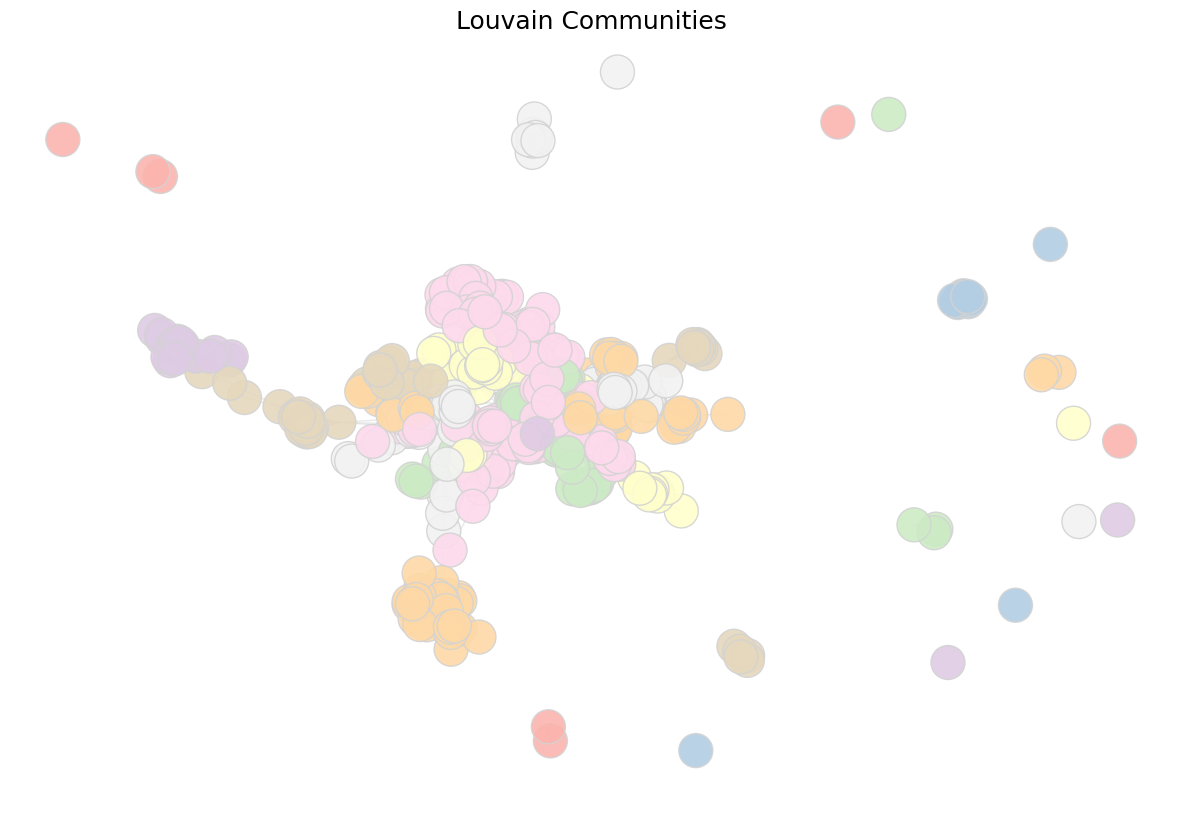

In [33]:
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from community import community_louvain
from mycolorpy import colorlist as mcp

def get_color_list(ncolors, cmap='Pastel1_r'):
    return mcp.gen_color(cmap=cmap, n=ncolors)

def analyze_and_draw_communities(G, node_size=600, alpha=0.9, layout_seed=42, cmap='Pastel1_r'):
    """
    Detects Louvain communities, plots the network with unique colors per community,
    and shows community size statistics and histogram.
    
    Parameters:
    - G: networkx.Graph
    - node_size: size of nodes in the network plot
    - alpha: transparency of nodes
    - layout_seed: seed for reproducible spring layout
    - cmap: colormap for communities
    """
    # 1️⃣ Louvain partition
    partition = community_louvain.best_partition(G)
    num_communities = len(set(partition.values()))
    print(f"Number of communities detected: {num_communities}")
    
    # 2️⃣ Community statistics
    community_sizes = {}
    for node, comm_id in partition.items():
        community_sizes[comm_id] = community_sizes.get(comm_id, 0) + 1

    sizes_list = list(community_sizes.values())
    print(f"Minimum community size: {np.min(sizes_list)}")
    print(f"Maximum community size: {np.max(sizes_list)}")
    print(f"Mean community size: {np.mean(sizes_list):.2f}")
    print(f"Median community size: {np.median(sizes_list)}")
    
    # Histogram of community sizes
    plt.figure(figsize=(10, 6))
    sns.histplot(sizes_list, bins=range(1, max(sizes_list) + 2), edgecolor='black')
    plt.title('Distribution of Community Sizes')
    plt.xlabel('Community Size (Number of Nodes)')
    plt.ylabel('Number of Communities')
    plt.xticks(range(1, max(sizes_list) + 2, max(1, max(sizes_list)//10)))
    plt.grid(axis='y', alpha=0.75)
    plt.show()
    
    # 3️⃣ Prepare node colors
    unique_communities = set(partition.values())
    colors = get_color_list(len(unique_communities), cmap)
    comm_to_color = {comm: color for comm, color in zip(unique_communities, colors)}
    node_colors = [comm_to_color[partition[n]] for n in G.nodes()]
    
    # 4️⃣ Draw network
    plt.figure(figsize=(15, 10))
    pos = nx.spring_layout(G, seed=layout_seed)
    
    nx.draw_networkx_edges(G, pos, edge_color='lightgray', alpha=0.5)
    nodes = nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=node_size, alpha=alpha)
    nodes.set_edgecolor('lightgrey')
    
    plt.title('Louvain Communities', size=18)
    plt.axis('off')
    plt.show()
    
    return partition, community_sizes

# Example usage:
partition, community_sizes = analyze_and_draw_communities(B_crimes, node_size=600)


# Infomap

In [34]:
def findCommunities_infomap(im, int_to_node=None):
    """
    Runs Infomap and returns:
    - partition: dict mapping REAL node labels -> community id
    - codelength: map equation value
    """

    im.run()  # run Infomap

    partition = {}

    for node in im.iterLeafNodes():
        # your Infomap version uses physicalId
        nid = node.physicalId

        # convert integer back to original label if provided
        if int_to_node is not None and nid in int_to_node:
            original_label = int_to_node[nid]
        else:
            original_label = nid

        partition[original_label] = node.moduleIndex()

    return partition, im.codelength  # your version uses codelength


  Infomap v2.8.0 starts at 2025-12-02 08:23:15
  -> Input network: 
  -> No file output!
  OpenMP 201511 detected with 16 threads...
  -> Ordinary network input, using the Map Equation for first order network flows
Calculating global network flow using flow model 'undirected'... 
  -> Using undirected links.
  => Sum node flow: 1, sum link flow: 1
Build internal network with 539 nodes and 2343 links...
  -> One-level codelength: 8.59811605

Trial 1/1 starting at 2025-12-02 08:23:15
Two-level compression: 42% 0.39% 0.213552132% 
Partitioned to codelength 0.500543538 + 4.48709686 = 4.987640399 in 48 modules.
Super-level compression: 2.62732909% to codelength 4.856598672 in 13 top modules.

Recursive sub-structure compression: 12.5155738% 13.908867% 0.0426470819% 0% . Found 5 levels with codelength 4.797953011

=> Trial 1/1 finished in 0.265492974s with codelength 4.79795301


Summary after 1 trial
Best end modular solution in 5 levels:
Per level number of modules:         [         13,  

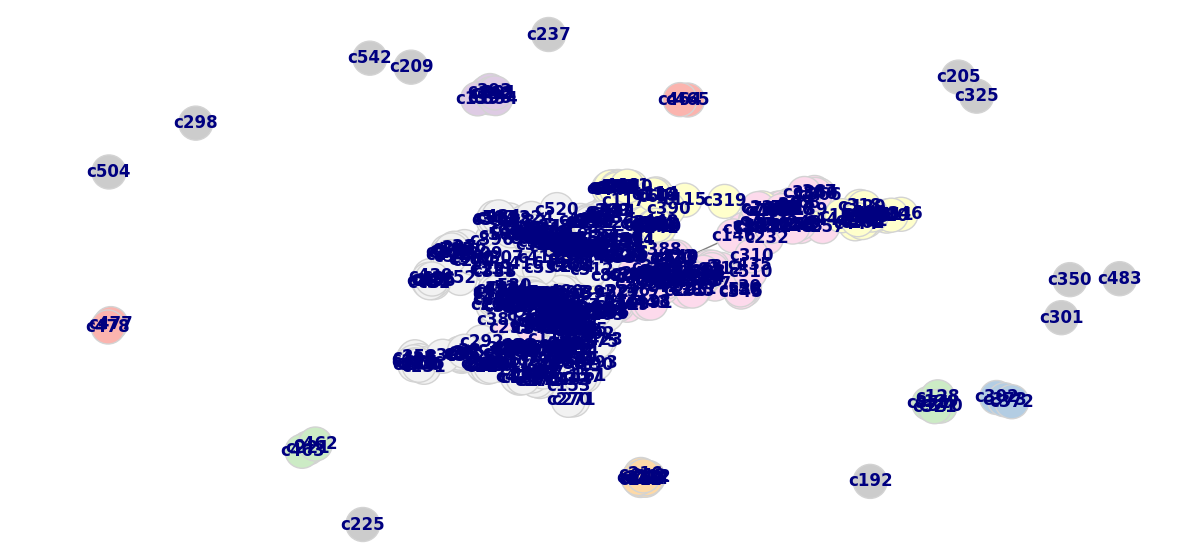

In [35]:
# integer mapping
node_to_int = {node: i for i, node in enumerate(B_crimes.nodes())}
int_to_node = {i: node for node, i in node_to_int.items()}

im_cr = Infomap()

for u, v in B_crimes.edges():
    im_cr.add_link(node_to_int[u], node_to_int[v])

# run Infomap
partition_infomap_cr, code_len = findCommunities_infomap(im_cr, int_to_node)


# community color palette
comm_index = set(partition_infomap_cr.values())
colors_infomap = {
    comm: c for comm, c in zip(comm_index, get_color_list(len(comm_index), 'Pastel1_r'))
}

fallback_color = "#cccccc"

# assign color to each node
colors_for_node_infomap_cr = {}
for node in B_crimes.nodes():
    if node in partition_infomap_cr:
        colors_for_node_infomap_cr[node] = colors_infomap[partition_infomap_cr[node]]
    else:
        colors_for_node_infomap_cr[node] = fallback_color

# draw
draw_community_graph(B_crimes, p_cr, colors_for_node_infomap_cr)


  Infomap v2.8.0 starts at Number of communities detected by Infomap: 13
Min community size: 2
Max community size: 200
Mean community size: 41.46
Median community size: 8.0
2025-12-02 08:23:16
  -> Input network: 
  -> No file output!
  OpenMP 201511 detected with 16 threads...
  -> Ordinary network input, using the Map Equation for first order network flows
Calculating global network flow using flow model 'undirected'... 
  -> Using undirected links.
  => Sum node flow: 1, sum link flow: 1
Build internal network with 539 nodes and 2343 links...
  -> One-level codelength: 8.59811605

Trial 1/1 starting at 2025-12-02 08:23:16
Two-level compression: 42% 0.39% 0.213552132% 
Partitioned to codelength 0.500543538 + 4.48709686 = 4.987640399 in 48 modules.
Super-level compression: 2.62732909% to codelength 4.856598672 in 13 top modules.

Recursive sub-structure compression: 12.5155738% 13.908867% 0.0426470819% 0% . Found 5 levels with codelength 4.797953011

=> Trial 1/1 finished in 0.2224355

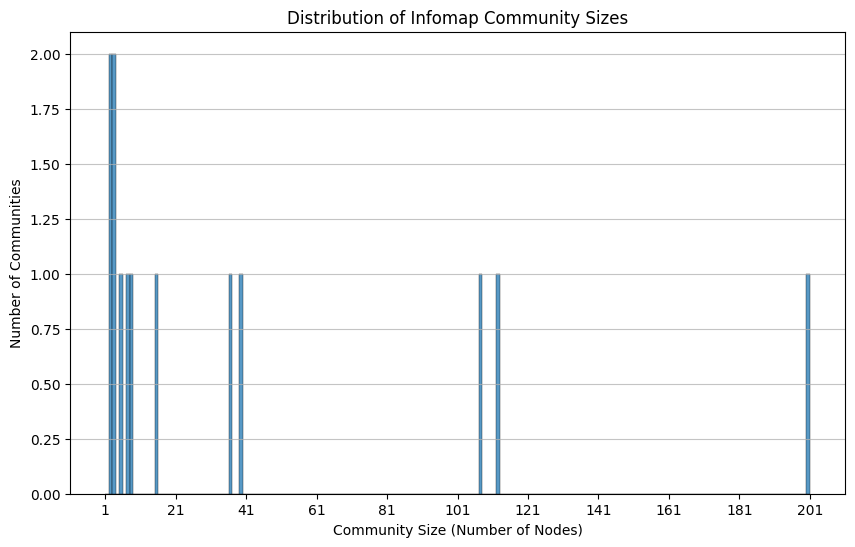

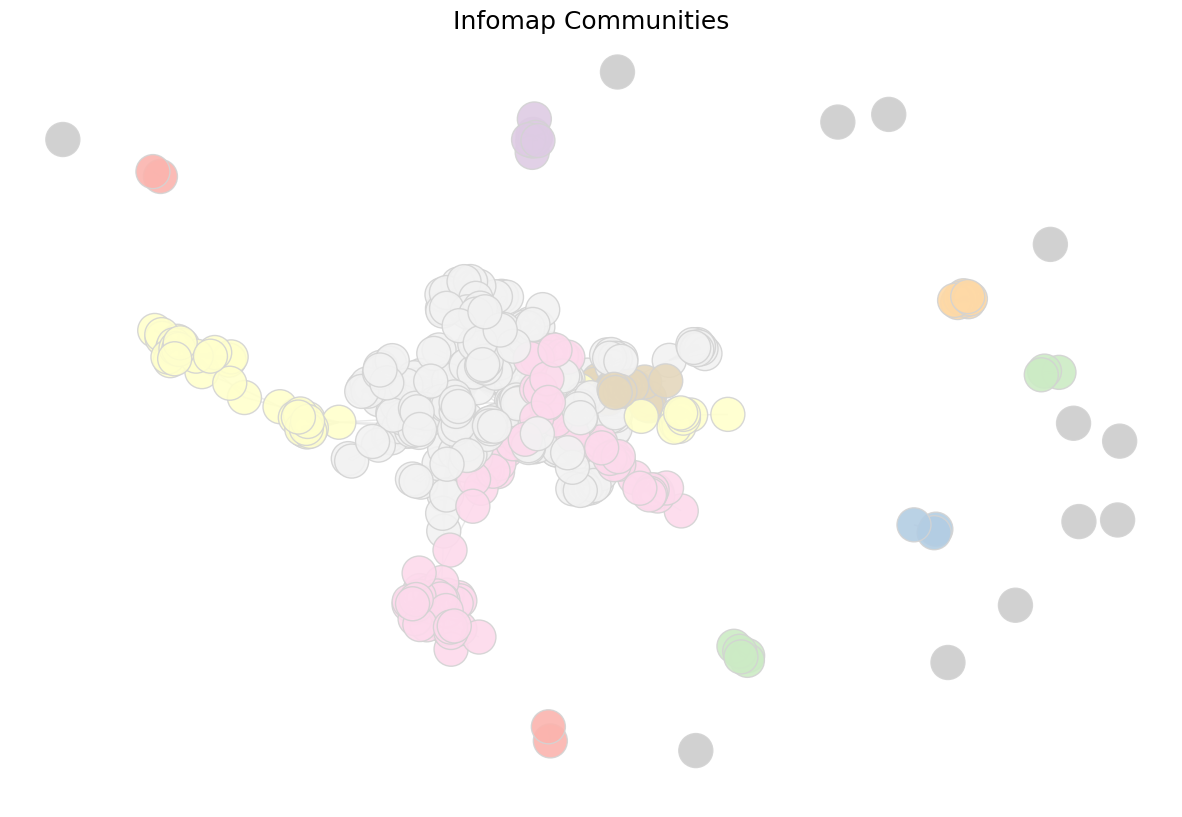

In [36]:
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from mycolorpy import colorlist as mcp
from infomap import Infomap  # make sure infomap package is installed

def get_color_list(ncolors, cmap='Pastel1_r'):
    return mcp.gen_color(cmap=cmap, n=ncolors)

def analyze_and_draw_infomap(G, node_size=600, alpha=0.9, layout_seed=42, cmap='Pastel1_r'):
    """
    Detects Infomap communities, plots the network with unique colors per community,
    and shows community size statistics and histogram.
    
    Parameters:
    - G: networkx.Graph
    - node_size: size of nodes in the network plot
    - alpha: transparency of nodes
    - layout_seed: seed for reproducible spring layout
    - cmap: colormap for communities
    """
    # 1️⃣ Map nodes to integers for Infomap
    node_to_int = {node: i for i, node in enumerate(G.nodes())}
    int_to_node = {i: node for node, i in node_to_int.items()}

    # 2️⃣ Run Infomap
    im = Infomap()
    for u, v in G.edges():
        im.add_link(node_to_int[u], node_to_int[v])
    im.run()
    
    # 3️⃣ Extract partition (community assignment)
    partition_int = {node.node_id: node.module_id for node in im.nodes}
    partition = {int_to_node[i]: comm for i, comm in partition_int.items()}
    
    num_communities = len(set(partition.values()))
    print(f"Number of communities detected by Infomap: {num_communities}")
    
    # 4️⃣ Community statistics
    community_sizes = {}
    for node, comm in partition.items():
        community_sizes[comm] = community_sizes.get(comm, 0) + 1
    
    sizes_list = list(community_sizes.values())
    print(f"Min community size: {np.min(sizes_list)}")
    print(f"Max community size: {np.max(sizes_list)}")
    print(f"Mean community size: {np.mean(sizes_list):.2f}")
    print(f"Median community size: {np.median(sizes_list)}")
    
    # Histogram
    plt.figure(figsize=(10, 6))
    sns.histplot(sizes_list, bins=range(1, max(sizes_list)+2), edgecolor='black')
    plt.title('Distribution of Infomap Community Sizes')
    plt.xlabel('Community Size (Number of Nodes)')
    plt.ylabel('Number of Communities')
    plt.xticks(range(1, max(sizes_list) + 2, max(1, max(sizes_list)//10)))
    plt.grid(axis='y', alpha=0.75)
    plt.show()
    
    # 5️⃣ Prepare node colors
    unique_communities = set(partition.values())
    colors = get_color_list(len(unique_communities), cmap)
    comm_to_color = {comm: color for comm, color in zip(unique_communities, colors)}
    
    # Ensure every node has a community color
    colors_for_node = {}
    for n in G.nodes():
        if n in partition:
            colors_for_node[n] = comm_to_color[partition[n]]
        else:
            colors_for_node[n] = "#cccccc"  # fallback grey

    node_colors = [colors_for_node[n] for n in G.nodes()]

    
    # 6️⃣ Draw network
    plt.figure(figsize=(15, 10))
    pos = nx.spring_layout(G, seed=layout_seed)
    
    nx.draw_networkx_edges(G, pos, edge_color='lightgray', alpha=0.5)
    nodes = nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=node_size, alpha=alpha)
    nodes.set_edgecolor('lightgrey')
    
    plt.title('Infomap Communities', size=18)
    plt.axis('off')
    plt.show()
    
    return partition, community_sizes

# Example usage:
partition_infomap, community_sizes_infomap = analyze_and_draw_infomap(B_crimes, node_size=600)


# Community Quality

In [37]:
# Louvain community sets for B_crimes
list_community_sets_louvain_cr = defaultdict(set)
for n, comm in partition_louvain_cr.items():
    list_community_sets_louvain_cr[comm].add(n)

# Infomap community sets for B_crimes
list_community_sets_infomap_cr = defaultdict(set)
for n, comm in partition_infomap_cr.items():
    list_community_sets_infomap_cr[comm].add(n)


In [38]:
partition_louvain_full = defaultdict(set)

# Add detected communities
for n, comm in partition_louvain_cr.items():
    partition_louvain_full[comm].add(n)

# Add missing nodes (crimes) to community -1
for node in B_crimes.nodes():
    if node not in partition_louvain_cr:
        partition_louvain_full[-1].add(node)


In [39]:
partition_infomap_full = defaultdict(set)

# Add detected communities
for n, comm in partition_infomap_cr.items():
    partition_infomap_full[comm].add(n)

# Add missing nodes (crimes)
for node in B_crimes.nodes():
    if node not in partition_infomap_cr:
        partition_infomap_full[-1].add(node)  # or different id


In [40]:
partition_louvain_sets = [frozenset(s) for s in partition_louvain_full.values()]
partition_infomap_sets = [frozenset(s) for s in partition_infomap_full.values()]


In [41]:
quality_matrix_cr = []

for partition in [partition_louvain_sets, partition_infomap_sets]:
    cov, perf = nx_comm.partition_quality(B_crimes, partition)
    quality_matrix_cr.append([cov, perf])

method_names = ["Louvain", "Infomap"]


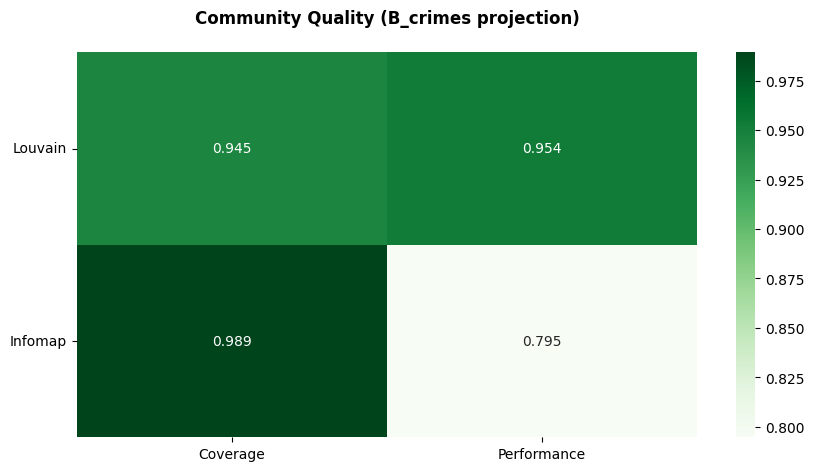

In [42]:
plt.figure(figsize=(10,5))

df_quality = pd.DataFrame(quality_matrix_cr, columns=["Coverage", "Performance"])

sns.heatmap(df_quality, annot=True, cmap="Greens", fmt=".3")

plt.xticks([0.5,1.5], ["Coverage","Performance"], rotation=0)
plt.yticks([0.5,1.5], method_names, rotation=0)

plt.title("Community Quality (B_crimes projection)\n", weight="bold")
plt.show()


# Community Size Distribution

# Louvain

In [43]:
#Louvain
comm_len_louvain = [(c, len(nodes)) for c, nodes in partition_louvain_full.items()]
comm_len_louvain.sort(key=lambda x: x[1], reverse=True)


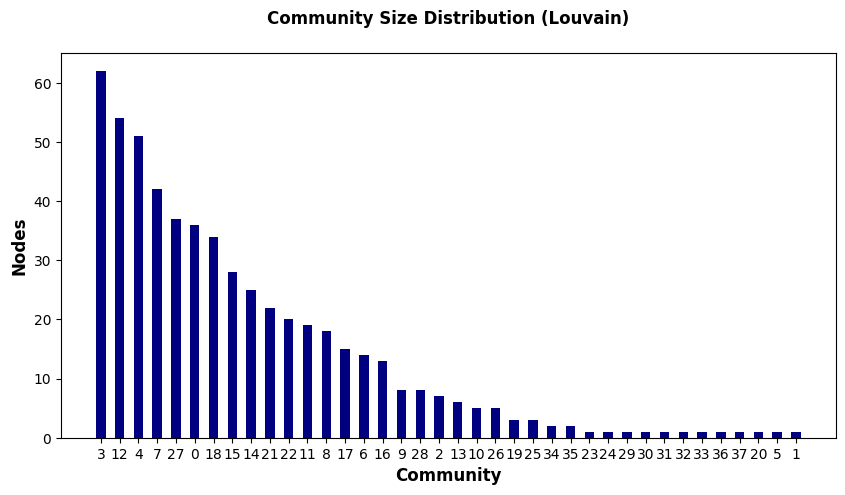

In [44]:
#Louvain Plot
plt.figure(figsize=(10,5))
plt.bar(range(len(comm_len_louvain)), [x[1] for x in comm_len_louvain], width=0.5, color='navy')

plt.xticks(range(len(comm_len_louvain)), [x[0] for x in comm_len_louvain])
plt.xlabel('Community', size=12, weight='bold')
plt.ylabel('Nodes', size=12, weight='bold')
plt.title("Community Size Distribution (Louvain)\n", weight='bold')
plt.show()


# Infomap

In [45]:
#Infomap
comm_len_infomap = [(c, len(nodes)) for c, nodes in partition_infomap_full.items()]
comm_len_infomap.sort(key=lambda x: x[1], reverse=True)

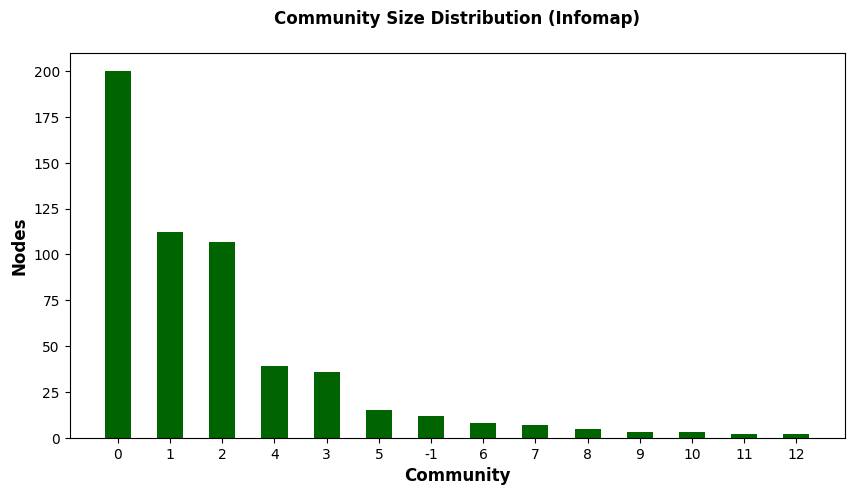

In [46]:
#Infomap Plot
plt.figure(figsize=(10,5))
plt.bar(range(len(comm_len_infomap)), [x[1] for x in comm_len_infomap], width=0.5, color='darkgreen')

plt.xticks(range(len(comm_len_infomap)), [x[0] for x in comm_len_infomap])
plt.xlabel('Community', size=12, weight='bold')
plt.ylabel('Nodes', size=12, weight='bold')
plt.title("Community Size Distribution (Infomap)\n", weight='bold')
plt.show()



# Community Graph

# Louvain 

In [47]:
# Louvain communities
comm_index_louvain = list(partition_louvain_full.keys())
colors_louvain_cr = {comm: c for comm, c in zip(comm_index_louvain, get_color_list(len(comm_index_louvain), 'Pastel1_r'))}

In [48]:
from community.community_louvain import induced_graph

# induced community graph — weight is computed automatically
ig_louvain = induced_graph(partition_louvain_cr, B_crimes)


In [49]:
edge_list_louvain = [(u, v, a['weight']) for u, v, a in ig_louvain.edges(data=True)]


In [50]:
df_edges_louvain = pd.DataFrame(edge_list_louvain,
                                columns=["source", "destination", "weight"])


In [51]:
ig_louvain_filtered = nx.from_pandas_edgelist(
    df_edges_louvain,
    "source", "destination",
    edge_attr="weight",
    create_using=nx.Graph()
)


In [52]:
color_map_louvain = {comm: colors_louvain_cr[comm] for comm in partition_louvain_full.keys()}


In [53]:
node_sizes_louvain = [
    len(partition_louvain_full[c]) * 200 for c in ig_louvain_filtered.nodes()
]


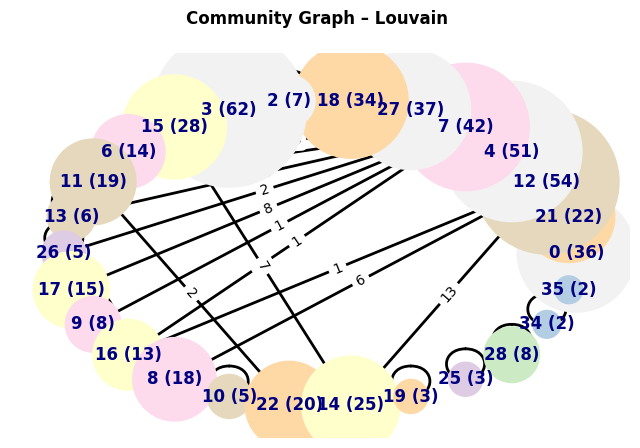

In [54]:
plt.figure(figsize=(8,5))
pos_louvain = nx.circular_layout(ig_louvain_filtered)

# node labels: community_id (#nodes)
labels_louvain = {
    c: f"{c} ({len(partition_louvain_full[c])})"
    for c in ig_louvain_filtered.nodes()
}

nx.draw_networkx(
    ig_louvain_filtered,
    pos=pos_louvain,
    labels=labels_louvain,
    node_color=[colors_louvain_cr[c] for c in ig_louvain_filtered.nodes()],
    node_size=node_sizes_louvain,
    font_color='navy',
    font_weight='bold',
    width=2
)

# edge labels: number of edges between communities
edge_labels_louvain = nx.get_edge_attributes(ig_louvain_filtered, 'weight')
nx.draw_networkx_edge_labels(ig_louvain_filtered, pos_louvain, edge_labels=edge_labels_louvain)

plt.title("Community Graph – Louvain \n", weight="bold")
plt.axis('off')
plt.show()


# Infomap

In [55]:
# Infomap communities
comm_index_infomap = list(partition_infomap_full.keys())
colors_infomap_cr = {comm: c for comm, c in zip(comm_index_infomap, get_color_list(len(comm_index_infomap), 'Pastel1_r'))}

In [56]:
# induced community graph — weight is computed automatically
ig_infomap = induced_graph(partition_louvain_cr, B_crimes)


In [57]:
edge_list_infomap = [(u, v, a['weight']) for u, v, a in ig_infomap.edges(data=True)]


In [58]:
df_edges_infomap = pd.DataFrame(edge_list_infomap,
                                columns=["source", "destination", "weight"])


In [59]:
ig_infomap_filtered = nx.from_pandas_edgelist(
    df_edges_infomap,
    "source",
    "destination",
    edge_attr="weight",
    create_using=nx.Graph()
)


In [60]:
color_map_infomap = {comm: colors_infomap_cr[comm] for comm in partition_infomap_full.keys()}

node_sizes_infomap = [
    len(partition_infomap_full[c]) * 200 for c in ig_infomap_filtered.nodes()
]


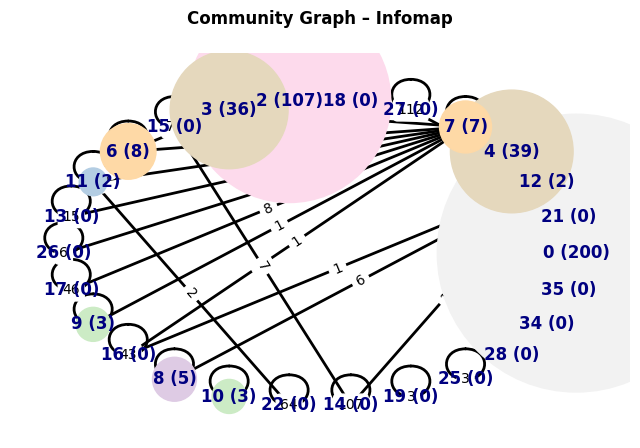

In [61]:
plt.figure(figsize=(8,5))
pos_infomap = nx.circular_layout(ig_infomap_filtered)

labels_infomap = {
    c: f"{c} ({len(partition_infomap_full[c])})"
    for c in ig_infomap_filtered.nodes()
}

nx.draw_networkx(
    ig_infomap_filtered,
    pos=pos_infomap,
    labels=labels_infomap,
    node_color=[colors_infomap_cr.get(c, "#cccccc") for c in ig_infomap_filtered.nodes()],
    node_size=node_sizes_infomap,
    font_color='navy',
    font_weight='bold',
    width=2
)

edge_labels_infomap = nx.get_edge_attributes(ig_infomap_filtered, 'weight')
nx.draw_networkx_edge_labels(ig_infomap_filtered, pos_infomap, edge_labels=edge_labels_infomap)

plt.title("Community Graph – Infomap\n", weight="bold")
plt.axis('off')
plt.show()


<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=da4a7319-aa5b-4e40-983e-e54de12bbb4e' target="_blank">

Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>